# S03-01 — RQ01 e RQ02: estatística descritiva (#167)

Frequência de deploy (RQ01) e lead time (RQ02) dos 500 repositórios da amostra final.

- Fonte: `entregas/s02-03-dataset-500-final/dataset-500.csv` (contrato `lab03-dataset-v1`, janela de 2025-10-01 a 2026-10-01, exclusivo).
- Cada métrica é resumida só pelos valores válidos. Ausências não viram zero e o `n` de cada métrica aparece nas tabelas.
- Quartis por interpolação linear (padrão do pandas); IQR = Q3 − Q1.
- Saídas: `tabelas/` (CSV) e `figuras/` (PNG). Reexecute com *Run All* a partir desta pasta.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))
from pipeline.classificacao import DIA, MES, SEMANA
from pipeline.descritiva import SEMANAS_POR_MES, carregar_dataset, comparar_variantes, pares_lead_time, tabela_resumo

DATASET = RAIZ / "entregas" / "s02-03-dataset-500-final" / "dataset-500.csv"
FIGURAS, TABELAS = Path("figuras"), Path("tabelas")
FIGURAS.mkdir(exist_ok=True)
TABELAS.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
TINTA, TINTA_CLARA, CORTE = "#333333", "#999999", "#777777"

# Formato de artigo: as figuras entram com meia largura do texto do SBC
# (0.49\textwidth), então são desenhadas nesse tamanho, com fonte de 8 pt.
from matplotlib.ticker import FuncFormatter

plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
                     "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "axes.linewidth": 0.6,
                     "xtick.major.width": 0.6, "ytick.major.width": 0.6, "grid.color": "#e6e6e6",
                     "grid.linewidth": 0.5})
MEIA_LARGURA = 3.1


def numero_pt(valor, _=None):
    """Rótulo de eixo em português: 0,1 / 1 / 10 / 1.000."""
    if valor >= 1:
        return f"{valor:,.0f}".replace(",", ".")
    return f"{valor:g}".replace(".", ",")


EIXO_PT = FuncFormatter(numero_pt)
CAIXA = {"flierprops": {"marker": "o", "markersize": 2, "markerfacecolor": "none",
                        "markeredgecolor": TINTA_CLARA, "markeredgewidth": 0.5},
         "medianprops": {"color": TINTA, "linewidth": 1.4}, "boxprops": {"color": TINTA, "linewidth": 0.8},
         "whiskerprops": {"color": TINTA, "linewidth": 0.8}, "capprops": {"color": TINTA, "linewidth": 0.8}}


def caixa_log(ax, series, rotulos, widths):
    """Boxplot de Tukey calculado em log10 e desenhado em eixo log, para os bigodes
    respeitarem a escala mostrada (na escala linear, o bigode inferior vai ao mínimo)."""
    from matplotlib.cbook import boxplot_stats
    estatisticas = []
    for valores, rotulo in zip(series, rotulos):
        positivos = valores[valores > 0]
        e = boxplot_stats(np.log10(positivos), labels=[rotulo])[0]
        for chave in ("med", "q1", "q3", "whislo", "whishi", "mean"):
            e[chave] = 10 ** e[chave]
        e["fliers"] = 10 ** e["fliers"]
        estatisticas.append(e)
    ax.set_xscale("log")
    ax.bxp(estatisticas, vert=False, widths=widths, showmeans=False, **CAIXA)


def cortes(ax, posicoes, rotular=True):
    for rotulo, x in posicoes.items():
        ax.axvline(x, color=CORTE, linestyle="--", linewidth=0.7, zorder=0)
        if rotular:
            ax.annotate(rotulo, (x, 1), xycoords=("data", "axes fraction"), xytext=(2, -1),
                        textcoords="offset points", va="top", fontsize=6.5, color=TINTA)


def caixa_e_histograma(valores, posicoes, rotulo_x, arquivo):
    """Boxplot acima de um histograma em escala log, com os cortes DORA."""
    bins = np.logspace(np.log10(valores.min() * 0.9), np.log10(valores.max() * 1.1), 26)
    fig, (ax_box, ax_hist) = plt.subplots(2, 1, sharex=True, figsize=(MEIA_LARGURA, 2.35),
                                          height_ratios=[1, 4], layout="constrained")
    caixa_log(ax_box, [valores], [""], widths=0.6)
    ax_box.set_yticks([])
    ax_box.grid(False)
    ax_box.spines["left"].set_visible(False)
    ax_box.tick_params(axis="x", which="both", length=0)
    ax_hist.hist(valores, bins=bins, color=TINTA_CLARA, edgecolor="white", linewidth=0.5)
    cortes(ax_box, posicoes, rotular=False)
    cortes(ax_hist, posicoes)
    ax_hist.set_xscale("log")
    ax_hist.xaxis.set_major_formatter(EIXO_PT)
    ax_hist.grid(axis="x", visible=False)
    ax_hist.set_xlabel(rotulo_x)
    ax_hist.set_ylabel("Repositórios")
    fig.savefig(FIGURAS / arquivo)
    return fig


def caixas_por_variante(series, posicoes, rotulo_x, arquivo, log=False):
    """Um boxplot horizontal por variante, com os cortes DORA."""
    fig, ax = plt.subplots(figsize=(MEIA_LARGURA, 1.75), layout="constrained")
    if log:
        caixa_log(ax, list(series.values()), list(series), widths=0.5)
        ax.xaxis.set_major_formatter(EIXO_PT)
    else:
        ax.boxplot(list(series.values()), vert=False, widths=0.5, tick_labels=list(series), **CAIXA)
    cortes(ax, posicoes)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(rotulo_x)
    fig.savefig(FIGURAS / arquivo)
    return fig

dados = carregar_dataset(DATASET)
pd.options.display.float_format = "{:,.3f}".format
print(f"{len(dados)} repositórios; janela {dados.janela_inicio.iloc[0]} a {dados.janela_fim_exclusivo.iloc[0]}")

500 repositórios; janela 2025-10-01T00:00:00Z a 2026-10-01T00:00:00Z


## RQ01 — Frequência de deploy

DF = releases estáveis na janela / semanas reais da janela. A coluna em releases/mês só reescala a DF (× 365,25/7/12 ≈ 4,35) para comparar com a hipótese de uma a três releases por mês.

In [2]:
dados["df_mes"] = dados["deployment_frequency"] * SEMANAS_POR_MES
rq01 = tabela_resumo(dados, {
    "DF (releases/semana)": "deployment_frequency",
    "DF (releases/mês)": "df_mes",
})
rq01.to_csv(TABELAS / "rq01_resumo.csv", index=False)
rq01

,metrica,n,ausentes,minimo,q1,mediana,q3,iqr,maximo,media
0,DF (releases/semana),500,0,0.096,0.230,0.479,1.132,0.901,51.263,1.314
1,DF (releases/mês),500,0,0.417,1.001,2.085,4.920,3.919,222.903,5.713


In [3]:
df_mes = dados["df_mes"].dropna()
faixas = pd.Series({
    "< 1 release/mês": (df_mes < 1).sum(),
    "1 a 3 releases/mês": df_mes.between(1, 3).sum(),
    "> 3 releases/mês": (df_mes > 3).sum(),
}, name="repositorios").to_frame()
faixas["percentual"] = 100 * faixas["repositorios"] / len(df_mes)
faixas.to_csv(TABELAS / "rq01_faixas_mensais.csv")
faixas

,repositorios,percentual
< 1 release/mês,120,24.000
1 a 3 releases/mês,183,36.600
> 3 releases/mês,197,39.400


C:\Users\Jonathan\AppData\Local\Temp\ipykernel_13988\727282131.py:63: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.bxp(estatisticas, vert=False, widths=widths, showmeans=False, **CAIXA)


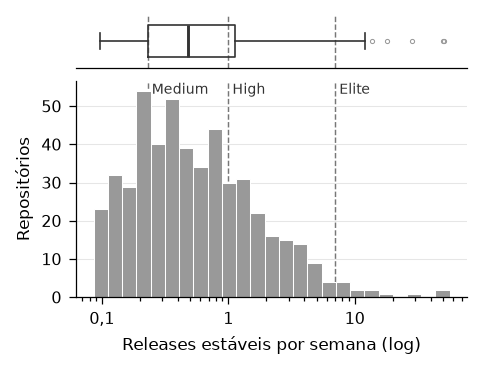

In [4]:
df = dados["deployment_frequency"].dropna()
cortes_df = {"Medium": 12 * 7 / 365, "High": 1, "Elite": 7}
fig = caixa_e_histograma(df, cortes_df, "Releases estáveis por semana (log)", "rq01_frequencia_deploy.png")
plt.show()

## RQ02 — Lead time

Variante (a): mediana, por release, de publicação − commit mais antigo. Variante (b): mediana de todos os pares commit–release. Ambas em horas.

Repositórios sem compare válido ficam fora do resumo; o `n` de cada variante está na tabela.

In [5]:
for variante in ("a", "b"):
    dados[f"lead_time_{variante}_dias"] = dados[f"lead_time_{variante}"] / DIA
rq02 = tabela_resumo(dados, {
    "Lead time (a), horas": "lead_time_a",
    "Lead time (b), horas": "lead_time_b",
    "Lead time (a), dias": "lead_time_a_dias",
    "Lead time (b), dias": "lead_time_b_dias",
})
rq02.to_csv(TABELAS / "rq02_resumo.csv", index=False)
rq02

,metrica,n,ausentes,minimo,q1,mediana,q3,iqr,maximo,media
0,"Lead time (a), horas",499,1,0.008,91.107,268.020,928.012,836.905,"50,633.772","1,876.069"
1,"Lead time (b), horas",499,1,0.008,79.463,303.217,"1,225.320","1,145.857","107,152.055","2,003.623"
2,"Lead time (a), dias",499,1,0.000,3.796,11.167,38.667,34.871,"2,109.741",78.170
3,"Lead time (b), dias",499,1,0.000,3.311,12.634,51.055,47.744,"4,464.669",83.484


### Comparação das variantes (a) e (b)

Pares do mesmo repositório. Diferença = (a) − (b), em horas; razão = (a) / (b). A hipótese da RQ02 espera (a) > (b).

In [6]:
pares = pares_lead_time(dados)
pares.to_csv(TABELAS / "rq02_pares_variantes.csv", index=False)
comparacao = pd.Series(comparar_variantes(pares), name="valor", dtype=object).to_frame()
comparacao.to_csv(TABELAS / "rq02_comparacao_variantes.csv")
display(pares.head(10))
comparacao

,id,full_name,lead_time_a,lead_time_b,diferenca,razao
0,8514,rails/rails,"40,313.957","12,554.201","27,759.757",3.211
1,156018,redis/redis,"10,274.714","20,646.767","-10,372.052",0.498
2,237159,expressjs/express,"10,700.924","9,766.233",934.691,1.096
3,458058,symfony/symfony,"12,205.901","10,636.576","1,569.325",1.148
4,507775,elastic/elasticsearch,"9,355.214","6,081.042","3,274.172",1.538
5,529502,scrapy/scrapy,"1,058.876",477.286,581.591,2.219
6,557980,socketio/socket.io,492.904,"107,152.055","-106,659.151",0.005
7,569041,curl/curl,"7,182.561",739.559,"6,443.001",9.712
8,571770,jgm/pandoc,726.085,344.762,381.323,2.106
9,576201,mrdoob/three.js,"1,774.586",836.390,938.196,2.122


,valor
n_pares,499
a_maior,303
iguais,1
a_menor,195
mediana_diferenca,27.567
mediana_razao,1.294


C:\Users\Jonathan\AppData\Local\Temp\ipykernel_13988\727282131.py:63: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.bxp(estatisticas, vert=False, widths=widths, showmeans=False, **CAIXA)


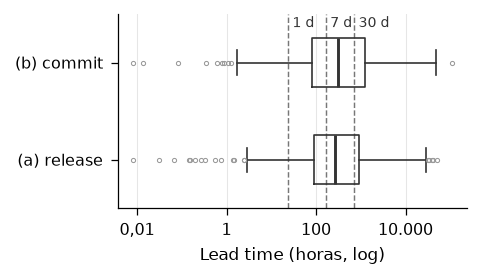

In [7]:
cortes_lt = {"1 d": DIA, "7 d": SEMANA, "30 d": MES}
variantes = {"(a) release": pares["lead_time_a"], "(b) commit": pares["lead_time_b"]}
fig = caixas_por_variante(variantes, cortes_lt, "Lead time (horas, log)", "rq02_lead_time_variantes.png", log=True)
plt.show()

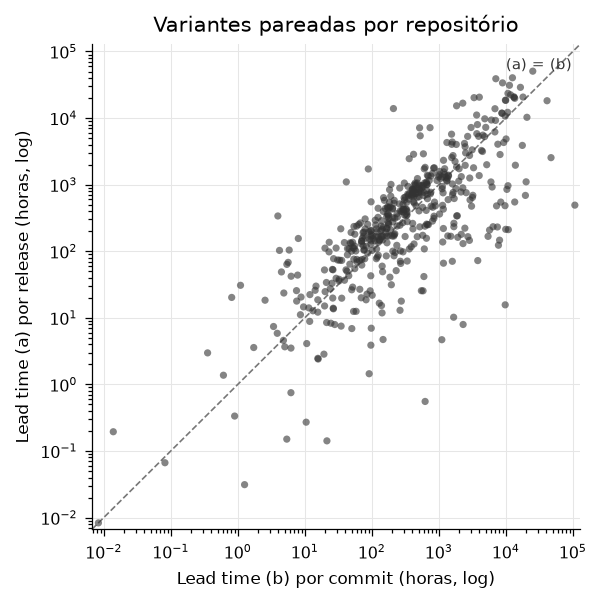

In [8]:
limites = [pares[["lead_time_a", "lead_time_b"]].min().min() * 0.8, pares[["lead_time_a", "lead_time_b"]].max().max() * 1.2]

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.plot(limites, limites, color=CORTE, linestyle="--", linewidth=0.8, zorder=1)
ax.annotate("(a) = (b)", (limites[1], limites[1]), xytext=(-4, -12), textcoords="offset points",
            ha="right", fontsize=7, color=TINTA)
ax.scatter(pares["lead_time_b"], pares["lead_time_a"], s=12, color=TINTA, alpha=0.6, edgecolor="none", zorder=2)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(limites)
ax.set_ylim(limites)
ax.set_xlabel("Lead time (b) por commit (horas, log)")
ax.set_ylabel("Lead time (a) por release (horas, log)")
ax.set_title("Variantes pareadas por repositório", fontsize=10)
fig.savefig(FIGURAS / "rq02_lead_time_pareado.png")
plt.show()

## Limitações

- O lead time depende do compare entre releases; repositórios sem compare válido têm `lead_time_a`/`lead_time_b` nulos e ficam fora do resumo.
- A amostra não é aleatória: a ordem da coleta priorizou custo nos 561 primeiros candidatos avaliados (ver o funil na metodologia), o que limita a generalização.
- A classificação DORA das métricas fica na S03-03 (#169).